# Exercise description

Implement three methods adapted to [problem description](data/problem-description.md):
- Random solution
- Nearest neighbor considering adding the node only at the end of the current path
- Nearest neighbor considering adding the node at all possible position, i.e. at the end, at the
beginning, or at any place inside the current path
- Greedy cycle

Ă˘â‚¬Ĺ›NearestĂ˘â‚¬ĹĄ neighbor should not be treated literally. We should always consider the best change of the
objective function, including distance and cost.

For each greedy method generate 200 solutions starting from each node. Generate also 200 random
solutions.

The report should contain:
- Description of the problem
- Pseudocode of all implemented algorithms
- Results of a computational experiment: for each instance and method min, max and average
value of the objective function.
- 2D visualization of the best solution for each instance and method. Cost of nodes should be
presented e.g. by a color, greyscale, or size.
- The best solutions for each instance and method presented as a list of nodes indices (starting
from 0).
- Information whether the best solutions have been checked with the solution checker.
- (Link to) the source code
- Conclusions

## Helpers and parameters

In [17]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path('data')
INSTANCES = ['TSPA', 'TSPB']
RNG_SEED = 0
NUM_OF_RANDOM_RUNS = 200

def load_instance(name: str):
    _p = DATA / f'{name}.csv'
    with open(_p) as _fh:
        _first = _fh.readline()
    _skip = 1 if any(c.isalpha() for c in _first) else 0
    d = np.loadtxt(_p, delimiter=';', skiprows=_skip, dtype=int)
    xy, costs = d[:, :2], d[:, 2]
    diff = xy[:, None, :] - xy[None, :, :]
    dist = np.rint(np.sqrt((diff ** 2).sum(axis=-1))).astype(int)
    n = len(costs)
    k = (n + 1) // 2
    return {'name': name, 'xy': xy, 'costs': costs, 'dist': dist, 'n': n, 'k': k}

problems = {name: load_instance(name) for name in INSTANCES}

def compute_cost(tour, dist: np.ndarray, costs: np.ndarray) -> int:
    t = np.asarray(tour, dtype=int)
    return int(dist[t, np.roll(t, -1)].sum() + costs[t].sum())

def check_solution(tour, n: int, k: int) -> tuple[bool, str]:
    """Used at the end to check solution's correctness"""
    t = list(tour)
    if len(t) != k:
        return False, f'length {len(t)} != k={k}'
    if len(set(t)) != k:
        return False, 'duplicate nodes'
    if any(not isinstance(v, (int, np.integer)) or v < 0 or v >= n for v in t):
        return False, 'index out of range'
    return True, 'ok'

problem = problems['TSPA']
t = list(range(problem['k']))

## Search method definitions

In [18]:
def random_tour(n: int, k: int, rng: np.random.Generator) -> list[int]:
    """Browse the graph at random"""
    selected = rng.choice(n, size=k, replace=False)
    rng.shuffle(selected)
    return [int(v) for v in selected]

def nearest_neighbor_at_end(start: int, distances: np.ndarray, costs: np.ndarray, k: int) -> list[int]:
    """Insert nearest neighbor at the end of path

    :param k: number of nearest neighbors to take into account
    """
    n = len(costs)
    tour = [int(start)]
    used = np.zeros(n, bool); used[start] = True
    for _ in range(1, k):
        last = tour[-1]
        cand = np.flatnonzero(~used)
        vals = distances[last, cand] + costs[cand]
        nxt = int(cand[int(np.argmin(vals))])
        tour.append(nxt); used[nxt] = True
    return tour

def nearest_neighbor_anywhere(start: int, distances: np.ndarray, costs: np.ndarray, k: int) -> list[int]:
    """Insert nearest neighbor in any place in the current path

    :param k: number of nearest neighbors to take into account
    """
    n = len(costs)
    tour = [int(start)]
    used = np.zeros(n, bool); used[start] = True
    for _ in range(1, k):
        cand = np.flatnonzero(~used)
        t = np.asarray(tour, dtype=int); m = len(t)
        D = distances[np.ix_(cand, t)]
        best = D[:, 0].astype(np.int64).copy()
        pos = np.zeros(len(cand), dtype=int)
        d_end = D[:, -1]
        upd = d_end < best; best[upd] = d_end[upd]; pos[upd] = m
        if m > 1:
            seg = distances[t[:-1], t[1:]]
            ins = D[:, :-1] + D[:, 1:] - seg[None, :]
            j = np.argmin(ins, axis=1)
            v = ins[np.arange(len(cand)), j]
            upd = v < best; best[upd] = v[upd]; pos[upd] = j[upd] + 1
        best = best + costs[cand]
        i = int(np.argmin(best))
        tour.insert(int(pos[i]), int(cand[i])); used[cand[i]] = True
    return tour

def greedy_cycle(start: int, dist: np.ndarray, costs: np.ndarray, k: int) -> list[int]:
    """Greedily form a cycle

    :param k: number of nearest neighbors to take into account
    """
    n = len(costs)
    tour = [int(start)]
    used = np.zeros(n, bool); used[start] = True
    for _ in range(1, k):
        cand = np.flatnonzero(~used)
        t = np.asarray(tour, dtype=int); m = len(t)
        if m == 1:
            delta = 2 * dist[int(start), cand] + costs[cand]
            i = int(np.argmin(delta))
            tour.append(int(cand[i])); used[cand[i]] = True
            continue
        nxt = np.roll(t, -1)
        seg = dist[t, nxt]                    # (m,)
        ins = dist[np.ix_(cand, t)] + dist[np.ix_(cand, nxt)] - seg[None, :]  # (C, m)
        j = np.argmin(ins, axis=1)
        v = ins[np.arange(len(cand)), j] + costs[cand]
        i = int(np.argmin(v))
        tour.insert(int(j[i]) + 1, int(cand[i])); used[cand[i]] = True
    return tour

## Compare the methods

In [19]:
rng = np.random.default_rng(RNG_SEED)
for fn in (lambda s, D, C, k: random_tour(problem['n'], problem['k'], rng), nearest_neighbor_at_end, nearest_neighbor_anywhere, greedy_cycle):
    tt = fn(0, problem['dist'], problem['costs'], problem['k'])
    print(fn.__name__ if hasattr(fn, '__name__') else fn, compute_cost(tt, problem['dist'], problem['costs']), check_solution(tt, problem['n'], problem['k']))

<lambda> 252162 (True, 'ok')
nearest_neighbor_at_end 88750 (True, 'ok')
nearest_neighbor_anywhere 74371 (True, 'ok')
greedy_cycle 73758 (True, 'ok')


In [20]:
results, best_tours, timings = {}, {}, {}
rng = np.random.default_rng(RNG_SEED)
for name in INSTANCES:
    pr = problems[name]
    n, k, dist, costs = pr['n'], pr['k'], pr['dist'], pr['costs']
    results[name], best_tours[name], timings[name] = {}, {}, {}
    t0 = time.perf_counter()
    tours = [random_tour(n, k, rng) for _ in range(NUM_OF_RANDOM_RUNS)]
    vals = np.array([compute_cost(t, dist, costs) for t in tours])
    results[name]['random'] = vals
    best_tours[name]['random'] = tours[int(np.argmin(vals))]
    timings[name]['random'] = time.perf_counter() - t0
    for mname, fn in [('nearest_neighbor_at_end', nearest_neighbor_at_end), ('nearest_neighbor_anywhere', nearest_neighbor_anywhere), ('greedy_cycle', greedy_cycle)]:
        t0 = time.perf_counter()
        tours = [fn(s, dist, costs, k) for s in range(n)]
        vals = np.array([compute_cost(t, dist, costs) for t in tours])
        results[name][mname] = vals
        best_tours[name][mname] = tours[int(np.argmin(vals))]
        timings[name][mname] = time.perf_counter() - t0
        print(f'{name}/{mname}: min_cost={vals.min()} max_cost={vals.max()} mean_cost={vals.mean():.1f} ({timings[name][mname]:.1f}s)')
    print(f"{name}/random: min={results[name]['random'].min()} max={results[name]['random'].max()} mean={results[name]['random'].mean():.1f} ({timings[name]['random']:.1f}s)")

TSPA/nearest_neighbor_at_end: min_cost=84362 max_cost=90075 mean_cost=87476.6 (0.2s)
TSPA/nearest_neighbor_anywhere: min_cost=72328 max_cost=77022 mean_cost=74347.0 (2.9s)
TSPA/greedy_cycle: min_cost=72590 max_cost=75281 mean_cost=73793.4 (3.8s)
TSPA/random: min=237157 max=289146 mean=263626.5 (0.0s)
TSPB/nearest_neighbor_at_end: min_cost=56007 max_cost=63166 mean_cost=59397.3 (0.2s)
TSPB/nearest_neighbor_anywhere: min_cost=52915 max_cost=66164 mean_cost=59480.3 (2.5s)
TSPB/greedy_cycle: min_cost=55655 max_cost=63734 mean_cost=59649.9 (4.3s)
TSPB/random: min=188874 max=232618 mean=207052.8 (0.0s)


In [21]:
rows = []
for name in INSTANCES:
    for mname in ['random', 'nearest_neighbor_at_end', 'nearest_neighbor_anywhere', 'greedy_cycle']:
        v = results[name][mname]
        rows.append({'instance': name, 'method': mname, 'min_cost': int(v.min()),
                       'max_cost': int(v.max()), 'mean_cost': float(v.mean()),
                       'time_s': round(timings[name][mname], 2)})
summary = pd.DataFrame(rows).set_index(['instance', 'method'])
summary

min_cost  max_cost   mean_cost  time_s
instance method                                                           
TSPA     random                       237157    289146  263626.450    0.01
         nearest_neighbor_at_end       84362     90075   87476.630    0.18
         nearest_neighbor_anywhere     72328     77022   74346.965    2.88
         greedy_cycle                  72590     75281   73793.405    3.79
TSPB     random                       188874    232618  207052.815    0.01
         nearest_neighbor_at_end       56007     63166   59397.335    0.21
         nearest_neighbor_anywhere     52915     66164   59480.275    2.55
         greedy_cycle                  55655     63734   59649.910    4.31

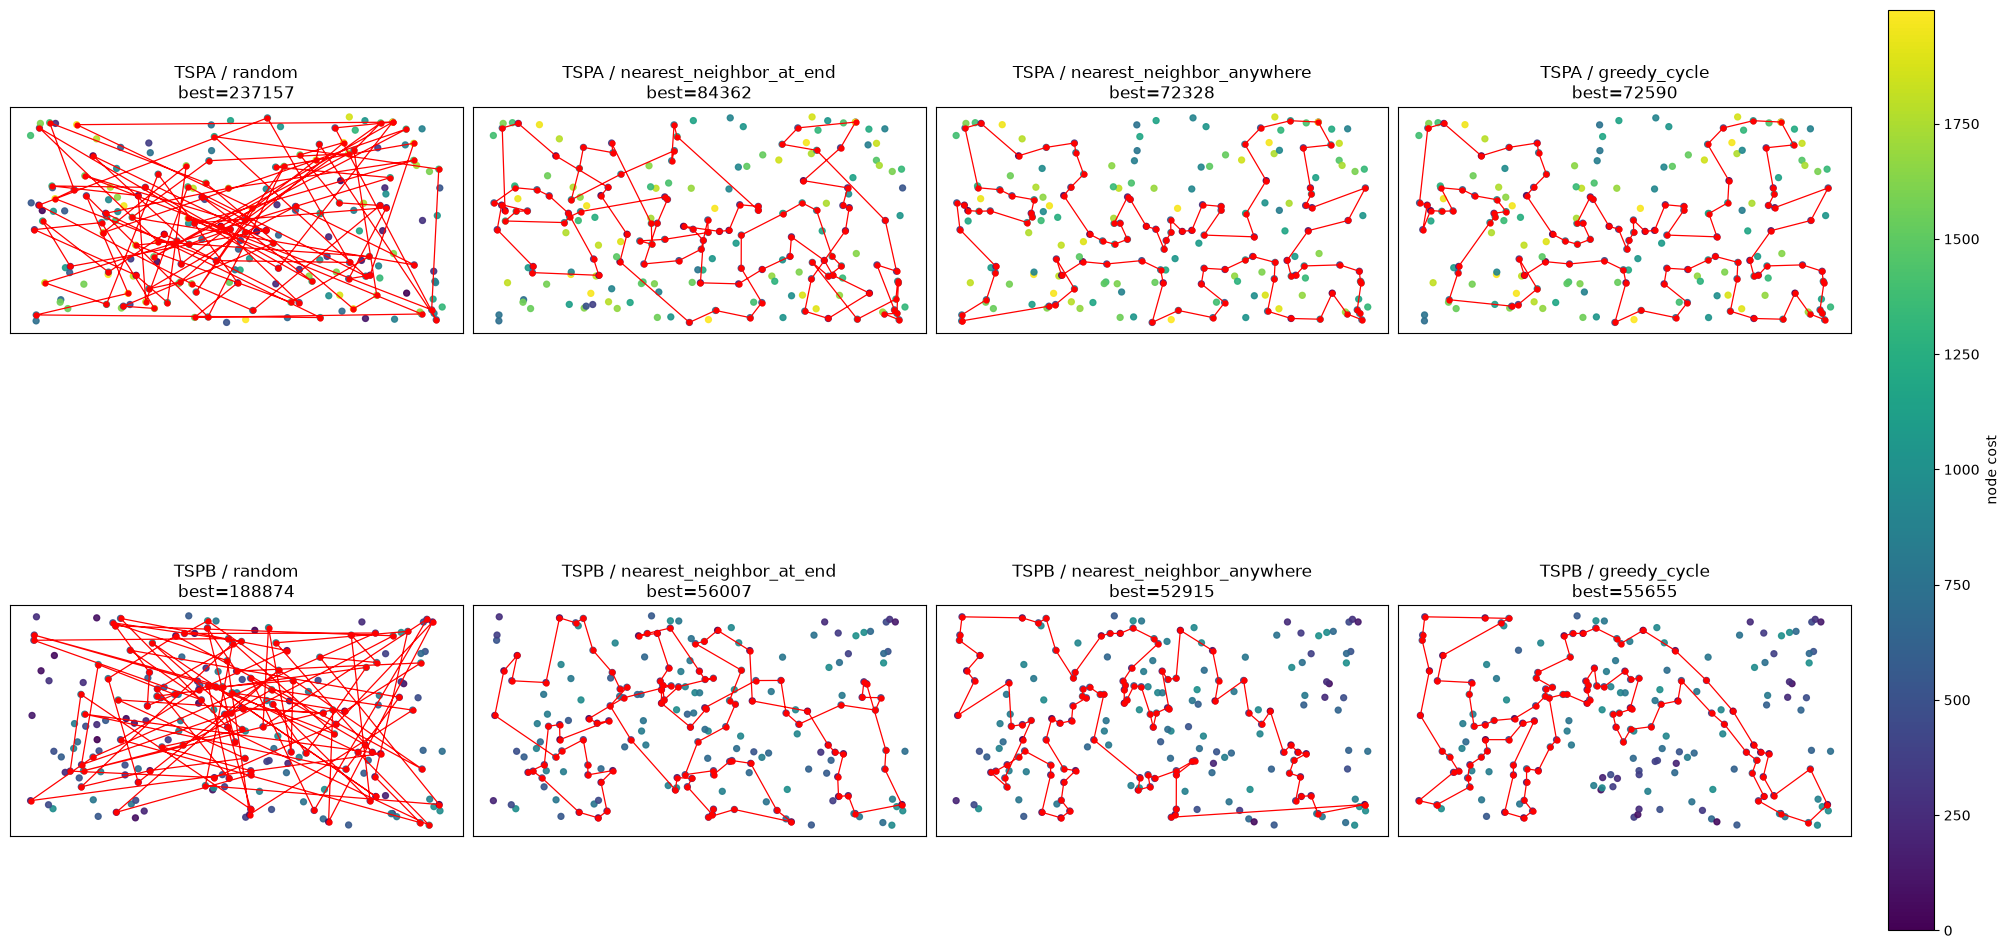

In [22]:
from matplotlib.colors import Normalize

all_costs = np.concatenate([problems[n]['costs'] for n in INSTANCES])
norm = Normalize(vmin=int(all_costs.min()), vmax=int(all_costs.max()))
sm = plt.cm.ScalarMappable(norm=norm, cmap='viridis')

with plt.style.context('default'):
    fig, axes = plt.subplots(2, 4, figsize=(20, 10), constrained_layout=True)
    fig.patch.set_facecolor('white')
    for i, name in enumerate(INSTANCES):
        pr = problems[name]
        xy, costs = pr['xy'], pr['costs']
        for j, mname in enumerate(['random', 'nearest_neighbor_at_end', 'nearest_neighbor_anywhere', 'greedy_cycle']):
            ax = axes[i, j]
            ax.set_facecolor('white')
            tour = best_tours[name][mname]
            t = np.asarray(tour, dtype=int)
            c = compute_cost(t, pr['dist'], pr['costs'])
            ax.scatter(xy[:, 0], xy[:, 1], c=costs, cmap='viridis', norm=norm,
                       s=18, alpha=0.9, zorder=1)
            path = xy[np.append(t, t[0])]
            ax.plot(path[:, 0], path[:, 1], 'r-', lw=0.9, zorder=3)
            ax.scatter(path[:, 0], path[:, 1], c='red', s=12, zorder=4)
            ax.set_title(f'{name} / {mname}\nbest={c}')
            ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(sm, ax=axes, location='right', fraction=0.025, pad=0.02, label='node cost')
    plt.show()

## Final paths

In [23]:
METHOD_ORDER = ['random', 'nearest_neighbor_at_end', 'nearest_neighbor_anywhere', 'greedy_cycle']
for name in INSTANCES:
    pr = problems[name]
    print(f'=== {name} (n={pr["n"]}, k={pr["k"]}) ===')
    for mname in METHOD_ORDER:
        tour = best_tours[name][mname]
        cost = compute_cost(tour, pr['dist'], pr['costs'])
        print(f'{mname}:\ncost={cost}\nnode indices:', end=" ")
        print(tour)
        print()

=== TSPA (n=200, k=100) ===
random:
cost=237157
node indices: [12, 18, 10, 187, 168, 160, 183, 171, 99, 80, 102, 144, 172, 88, 22, 135, 4, 92, 188, 59, 62, 86, 89, 151, 50, 35, 46, 190, 123, 111, 129, 198, 152, 25, 15, 98, 74, 126, 79, 84, 31, 191, 43, 20, 23, 28, 87, 109, 186, 78, 136, 29, 145, 56, 139, 162, 130, 9, 179, 189, 27, 195, 34, 142, 3, 181, 70, 149, 39, 150, 45, 167, 108, 7, 133, 105, 124, 184, 19, 52, 51, 65, 76, 82, 132, 166, 196, 42, 5, 21, 153, 66, 36, 97, 119, 161, 180, 158, 67, 17]

nearest_neighbor_at_end:
cost=84362
node indices: [54, 9, 33, 36, 177, 67, 144, 53, 135, 58, 134, 176, 174, 106, 89, 107, 57, 182, 151, 93, 50, 3, 1, 164, 178, 29, 136, 186, 184, 47, 159, 130, 153, 78, 88, 193, 170, 146, 75, 64, 150, 42, 113, 43, 85, 142, 8, 131, 84, 158, 192, 181, 114, 141, 180, 132, 76, 80, 48, 31, 63, 149, 168, 97, 127, 187, 30, 123, 152, 108, 60, 116, 49, 11, 119, 160, 83, 90, 51, 16, 35, 87, 45, 140, 52, 179, 185, 28, 102, 156, 157, 71, 91, 38, 100, 4, 112, 139, 115, 

In [24]:
from pathlib import Path

# Save every best solution as paste-ready node ids:
#  - {instance}_{method}_ids.csv -> one node id per line, no header
#    (paste into column F, rows 3-102 of solution-checker.xlsx)
OUT = Path('solutions')
OUT.mkdir(exist_ok=True)
METHOD_ORDER = ['random', 'nearest_neighbor_at_end', 'nearest_neighbor_anywhere', 'greedy_cycle']
for _name in INSTANCES:
    for _m in METHOD_ORDER:
        _tour = [int(_v) for _v in best_tours[_name][_m]]
        with open(OUT / f'{_name}_{_m}_ids.csv', 'w') as _f:
            for _idx in _tour:
                _f.write(f'{_idx}\n')
        print(f'saved {OUT / (_name + "_" + _m + "_ids.csv")}')


saved solutions\TSPA_random_ids.csv
saved solutions\TSPA_nearest_neighbor_at_end_ids.csv
saved solutions\TSPA_nearest_neighbor_anywhere_ids.csv
saved solutions\TSPA_greedy_cycle_ids.csv
saved solutions\TSPB_random_ids.csv
saved solutions\TSPB_nearest_neighbor_at_end_ids.csv
saved solutions\TSPB_nearest_neighbor_anywhere_ids.csv
saved solutions\TSPB_greedy_cycle_ids.csv
